In [3]:
import os
dataset_path = "../data/chest_xray"
os.listdir(dataset_path)

['test', 'train', 'val']

In [5]:
train_path = os.path.join(dataset_path, "train")
os.listdir(train_path)


['NORMAL', 'PNEUMONIA']

In [6]:
normal_train = len(
    os.listdir(os.path.join(train_path, "NORMAL"))
)

pneumonia_train = len(
    os.listdir(os.path.join(train_path, "PNEUMONIA"))
)

print("Normal Train Images:", normal_train)
print("Pneumonia Train Images:", pneumonia_train)

Normal Train Images: 1342
Pneumonia Train Images: 3876


In [7]:
test_path = os.path.join(dataset_path, "test")

normal_test = len(
    os.listdir(os.path.join(test_path, "NORMAL"))
)

pneumonia_test = len(
    os.listdir(os.path.join(test_path, "PNEUMONIA"))
)

print("Normal Test Images:", normal_test)
print("Pneumonia Test Images:", pneumonia_test)

Normal Test Images: 234
Pneumonia Test Images: 390


In [8]:
total_images = (
    normal_train
    + pneumonia_train
    + normal_test
    + pneumonia_test
)

print("Total Images:", total_images)

Total Images: 5842


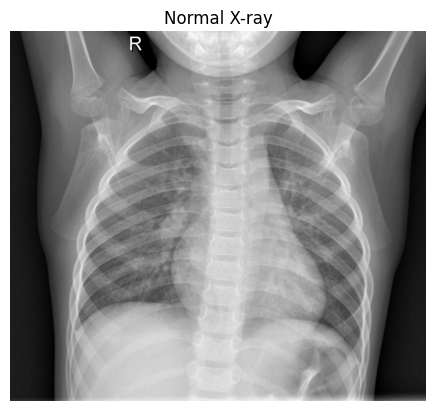

In [10]:
from PIL import Image
import matplotlib.pyplot as plt

normal_image_path = os.path.join(
    train_path,
    "NORMAL",
    os.listdir(os.path.join(train_path, "NORMAL"))[0]
)

img = Image.open(normal_image_path)

plt.imshow(img, cmap="gray")
plt.title("Normal X-ray")
plt.axis("off")
plt.show()

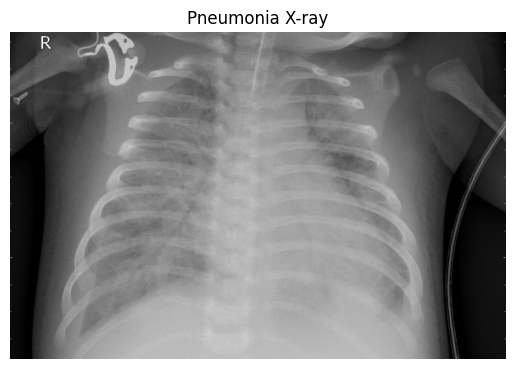

In [11]:
pneumonia_image_path = os.path.join(
    train_path,
    "PNEUMONIA",
    os.listdir(os.path.join(train_path, "PNEUMONIA"))[0]
)

img = Image.open(pneumonia_image_path)

plt.imshow(img, cmap="gray")
plt.title("Pneumonia X-ray")
plt.axis("off")
plt.show()

In [12]:
normal_train = len(
    os.listdir(os.path.join(train_path, "NORMAL"))
)

pneumonia_train = len(
    os.listdir(os.path.join(train_path, "PNEUMONIA"))
)

print("Normal Train Images:", normal_train)

print("Pneumonia Train Images:", pneumonia_train)

Normal Train Images: 1341
Pneumonia Train Images: 3875


In [13]:
test_path = os.path.join(dataset_path, "test")

normal_test = len(
    os.listdir(os.path.join(test_path, "NORMAL"))
)

pneumonia_test = len(
    os.listdir(os.path.join(test_path, "PNEUMONIA"))
)

print("Normal Test Images:", normal_test)

print("Pneumonia Test Images:", pneumonia_test)

Normal Test Images: 234
Pneumonia Test Images: 390


In [14]:
val_path = os.path.join(dataset_path, "val")

normal_val = len(
    os.listdir(os.path.join(val_path, "NORMAL"))
)

pneumonia_val = len(
    os.listdir(os.path.join(val_path, "PNEUMONIA"))
)

print("Normal Validation Images:", normal_val)
print("Pneumonia Validation Images:", pneumonia_val)

Normal Validation Images: 8
Pneumonia Validation Images: 8


In [15]:
total_images = (
    normal_train
    + pneumonia_train
    + normal_test
    + pneumonia_test
    + normal_val
    + pneumonia_val
)

print("Total Dataset Images:", total_images)

Total Dataset Images: 5856


In [16]:
print("Normal Image Size:", img.size)

Normal Image Size: (1152, 760)


 CNN Preprocessing & Augmentation Phase

In [18]:
%pip install tensorflow

  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached protobuf-7.34.1-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached typing_extensions-4.15.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached wrapt-2.1.2-cp312-cp312-win_amd64.whl.metadata (7.6 kB)
  Using cached grpcio-1.80.0-cp312-cp312-win_amd64.whl.metadata (3.9 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached charset_normalizer-3.4.7-cp312-cp312-win_amd64.whl.metadata (41 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
    --------------------------------------- 4.5/350.9 MB 24.4 MB/s eta 0:00:15
   - -------------------------------------- 9.4/350.9 MB 24.5 MB/s eta 0:00:14
   - -------------------------------------- 16.8/350.9 MB 28.5 MB/s eta 0:00:12
   -- ------------------------------------- 26.0/350.9 MB 32.9 MB/s eta 0:00:10
   ---- --------------------------


[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224       # 224x224 is standard size.
BATCH_SIZE = 32

In [20]:
# Train Data Augmentation 

train_datagen = ImageDataGenerator(

    rescale=1./255,

    rotation_range=15,

    zoom_range=0.15,

    width_shift_range=0.1,

    height_shift_range=0.1,

    shear_range=0.1,

    horizontal_flip=True,

    validation_split=0.2
)

In [21]:
test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [22]:
train_generator = train_datagen.flow_from_directory(

    train_path,

    target_size=(IMG_SIZE, IMG_SIZE),

    batch_size=BATCH_SIZE,

    class_mode="binary",

    subset="training"
)

Found 4173 images belonging to 2 classes.


In [23]:
val_generator = train_datagen.flow_from_directory(

    train_path,

    target_size=(IMG_SIZE, IMG_SIZE),

    batch_size=BATCH_SIZE,

    class_mode="binary",

    subset="validation"
)

Found 1043 images belonging to 2 classes.


CNN Model Building 

In [24]:
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

In [26]:
model = Sequential([
    
    Conv2D(
        32,
        (3,3),
        activation="relu",
        input_shape=(224,224,3)
    ),

    MaxPooling2D(2,2),
    
    Conv2D(
        64,
        (3,3),
        activation="relu"
    ),

    MaxPooling2D(2,2),
    
    Conv2D(
        128,
        (3,3),
        activation="relu"
    ),

    MaxPooling2D(2,2),

    
    Flatten(),

    
    Dense(128, activation="relu"),

    
    Dropout(0.5),

    Dense(1, activation="sigmoid")
])

model.summary()

d:\PneumoVision-AI\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(

    optimizer="adam",

    loss="binary_crossentropy",

    metrics=["accuracy"]
)

In [28]:
from tensorflow.keras.callbacks import (
    EarlyStopping
)

early_stop = EarlyStopping(

    monitor="val_loss",

    patience=3,

    restore_best_weights=True
)

 CNN Training 

In [30]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

print(train_generator.class_indices)

{'NORMAL': 0, 'PNEUMONIA': 1}


In [32]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_generator.classes),
    y=train_generator.classes
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: np.float64(1.9445479962721341), 1: np.float64(0.6730645161290323)}


In [33]:
history = model.fit(

    train_generator,
    validation_data=val_generator,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 181s 1s/step - accuracy: 0.7688 - loss: 0.4692 - val_accuracy: 0.8408 - val_loss: 0.4342
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 85s 648ms/step - accuracy: 0.8531 - loss: 0.3323 - val_accuracy: 0.8859 - val_loss: 0.2547
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 89s 679ms/step - accuracy: 0.8835 - loss: 0.2882 - val_accuracy: 0.8667 - val_loss: 0.2864
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 91s 696ms/step - accuracy: 0.8926 - loss: 0.2631 - val_accuracy: 0.8974 - val_loss: 0.2518
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 87s 664ms/step - accuracy: 0.9017 - loss: 0.2356 - val_accuracy: 0.9118 - val_loss: 0.1996
Epoch 6/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 86s 654ms/step - accuracy: 0.9027 - loss: 0.2451 - val_accuracy: 0.8811 - val_loss: 0.2689
Epoch 7/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 85s 652ms/step - accuracy: 0.8936 - loss: 0.2598 - val_accuracy: 0.6194 - val_loss: 0.8099
Epoch 8/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 88s 669ms/step - accuracy: 0.9017 - loss: 0.2

CNN Performance Evaluation 

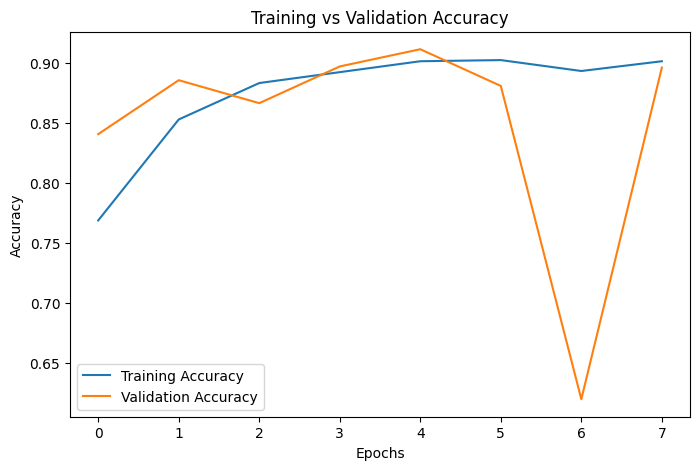

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

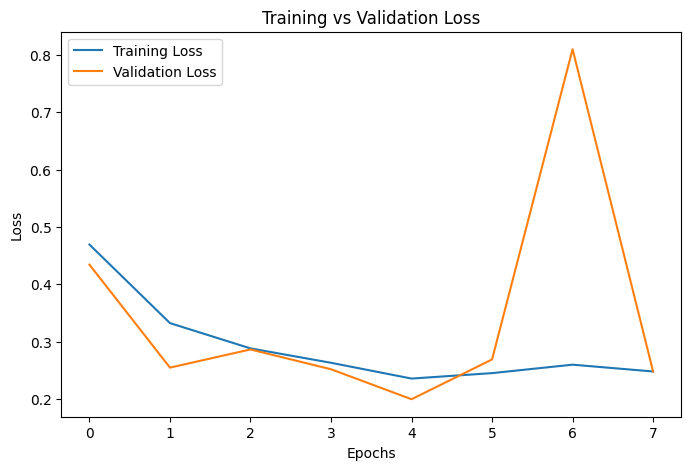

In [35]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Training vs Validation Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.show()

In [ ]:
test_generator = test_datagen.flow_from_directory(

    test_path,

    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 624 images belonging to 2 classes.


In [37]:
test_loss, test_accuracy = model.evaluate(
    test_generator
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 759ms/step - accuracy: 0.8205 - loss: 0.3731
Test Accuracy: 0.8205128312110901
Test Loss: 0.37307438254356384


In [39]:
predictions = model.predict(test_generator)
predicted_classes = (
    predictions > 0.5
).astype(int)

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 201ms/step


Advanced Evaluation

In [40]:
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

true_classes = test_generator.classes
print(
    classification_report(
        true_classes,
        predicted_classes
    )
)

              precision    recall  f1-score   support

           0       0.92      0.57      0.71       234
           1       0.79      0.97      0.87       390

    accuracy                           0.82       624
   macro avg       0.85      0.77      0.79       624
weighted avg       0.84      0.82      0.81       624



[[134 100]
 [ 12 378]]


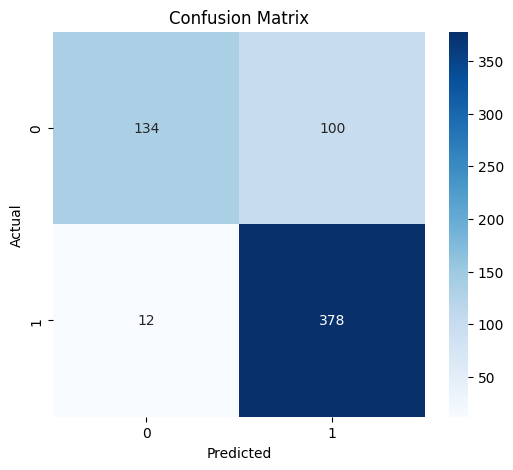

In [41]:
cm = confusion_matrix(
    true_classes,
    predicted_classes
)
print(cm)

plt.figure(figsize=(6,5))
sns.heatmap(

    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [42]:
model.save(
    "../models/pneumovision_cnn_model.h5"
)

In [43]:
import os
os.listdir("../models")

['pneumovision_cnn_model.h5']